# Sensor virtual de °Brix, HMF y color en un evaporador de jugo de manzana

**Problema real.** En una juguera, el °Brix del concentrado se mide con un refractómetro en línea. Si se ensucia o
falla, el control de °Brix queda ciego. El HMF y el color, en cambio, se miden en laboratorio cada pocas horas: cuando
llega un resultado fuera de especificación, ya se produjeron horas de concentrado fuera de especificación.

**Objetivo.** Un sensor virtual (*soft sensor*) que estime en tiempo real, solo con los instrumentos que ya existen
(temperaturas, presiones, caudales):
1. el **°Brix del concentrado**, como respaldo del refractómetro y para seguir controlando si este falla;
2. el **HMF** y el **color** del producto, minuto a minuto, entre un análisis de laboratorio y el siguiente.

**Datos.** Como los guardaría el historiador de la planta: 14 campañas de 24 h con una fila por minuto, más
2 campañas de **ensayo en planta** (alimentación en manual con escalones) y 176 análisis de laboratorio cada 2 h.
Se generan con el simulador del repositorio (`evaporador_jugo/`), con ruido de instrumentos y error de laboratorio.
Los valores reales (`real_*`) se usan **solo para evaluar**; los modelos se entrenan con lo que existiría en planta:
el refractómetro y el laboratorio.

In [1]:
import json, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
BASE=Path('..'); DAT=BASE/'datos'; FIG=BASE/'figuras'; MOD=BASE/'modelo'
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'font.size':9})
h=pd.read_csv(DAT/'historico.csv'); lab=pd.read_csv(DAT/'laboratorio.csv')
print('Historiador:',h.shape,' laboratorio:',lab.shape)
print(h.groupby('tipo').campana.nunique())

Historiador: (21136, 26)  laboratorio: (176, 4)
tipo
ensayo        2
operacion    14
Name: campana, dtype: int64


## 1. Exploración de una campaña
A lo largo de 24 h cambian el vapor vivo, el °Brix de la fruta y la temperatura del agua de enfriamiento (ciclo diario),
y los tubos se ensucian de a poco. El control de °Brix mueve la alimentación para compensar.

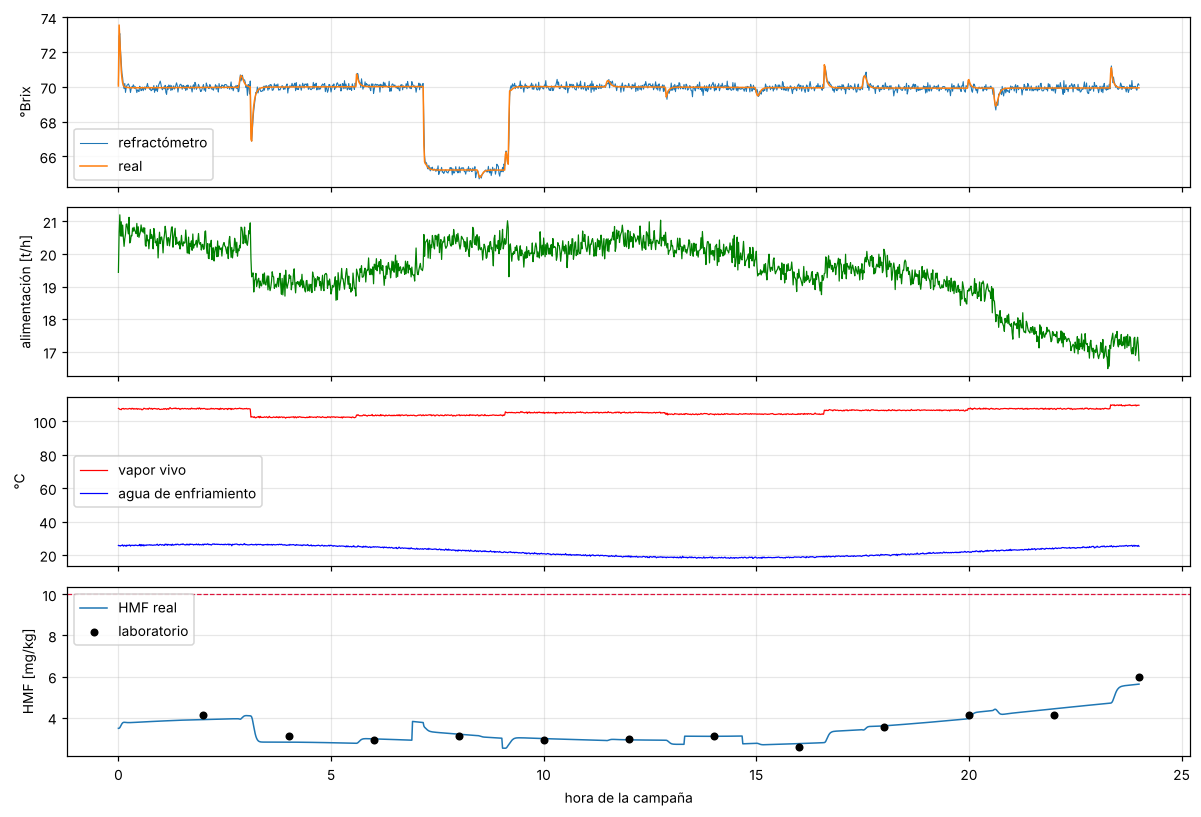

In [2]:
c=h[h.campana==3]; l3=lab[lab.campana==3]; t=c.t_min/60
fig,axs=plt.subplots(4,1,figsize=(11,7.5),sharex=True)
axs[0].plot(t,c.Brix_refract,lw=.7,label='refractómetro'); axs[0].plot(t,c.real_Brix,lw=1,label='real'); axs[0].set_ylabel('°Brix'); axs[0].legend(loc='lower left')
axs[1].plot(t,c.F_th,lw=.8,color='g'); axs[1].set_ylabel('alimentación [t/h]')
axs[2].plot(t,c.Ts,lw=.8,color='r',label='vapor vivo'); axs[2].plot(t,c.Tcw,lw=.8,color='b',label='agua de enfriamiento'); axs[2].set_ylabel('°C'); axs[2].legend(loc='center left')
axs[3].plot(t,c.real_HMF,lw=1,label='HMF real'); axs[3].scatter(l3.t_min/60,l3.HMF_lab,color='k',s=18,zorder=3,label='laboratorio'); axs[3].axhline(10,ls='--',color='crimson',lw=.8); axs[3].set_ylabel('HMF [mg/kg]'); axs[3].legend(loc='upper left')
axs[3].set_xlabel('hora de la campaña'); fig.tight_layout(); fig.savefig(FIG/'01_campana.png'); plt.show()

## 2. Verificación de la fenomenología de los datos
Antes de modelar se comprueba que los datos respeten la física. Si no la respetan, hay un problema de instrumentos
o de proceso que hay que resolver primero.
- **Arrhenius:** el HMF tiene que aumentar con la temperatura del vapor vivo.
- **Balance de masa:** en los ensayos en manual, más alimentación tiene que dar menos °Brix.
- **Elevación del punto de ebullición (EPE):** en el 5º efecto, $T_5 - T_{sat}(p_5)$ tiene que crecer con el °Brix.

corr(T vapor, HMF) = +0.72   corr(alimentación, °Brix) en ensayos = -0.65   corr(EPE5, °Brix) = +0.76


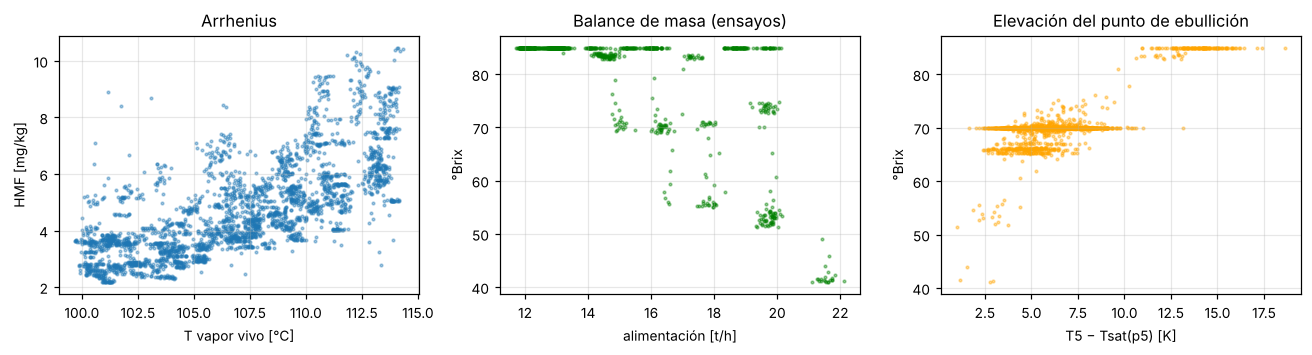

Chequeos de fenomenología de los datos: OK


In [3]:
def tsat(P): mm=P*7.50062; return 1730.63/(8.07131-np.log10(mm))-233.426
op=h[h.tipo=='operacion']; ens=h[h.tipo=='ensayo']
r1=np.corrcoef(op.Ts,op.real_HMF)[0,1]; r2=np.corrcoef(ens.F_th,ens.real_Brix)[0,1]; epe5=h.T5-tsat(h.P5); r3=np.corrcoef(epe5,h.real_Brix)[0,1]
print(f'corr(T vapor, HMF) = {r1:+.2f}   corr(alimentación, °Brix) en ensayos = {r2:+.2f}   corr(EPE5, °Brix) = {r3:+.2f}')
assert r1>0.3 and r2<-0.5 and r3>0.3
fig,axs=plt.subplots(1,3,figsize=(12,3.3))
axs[0].scatter(op.Ts[::7],op.real_HMF[::7],s=3,alpha=.4); axs[0].set_xlabel('T vapor vivo [°C]'); axs[0].set_ylabel('HMF [mg/kg]'); axs[0].set_title('Arrhenius')
axs[1].scatter(ens.F_th,ens.real_Brix,s=3,alpha=.4,color='g'); axs[1].set_xlabel('alimentación [t/h]'); axs[1].set_ylabel('°Brix'); axs[1].set_title('Balance de masa (ensayos)')
axs[2].scatter(epe5[::5],h.real_Brix[::5],s=3,alpha=.4,color='orange'); axs[2].set_xlabel('T5 − Tsat(p5) [K]'); axs[2].set_ylabel('°Brix'); axs[2].set_title('Elevación del punto de ebullición')
fig.tight_layout(); fig.savefig(FIG/'02_fenomenologia_datos.png'); plt.show()
print('Chequeos de fenomenología de los datos: OK')

## 3. Preparación: filtrado, rasgos físicos y partición por tiempo
- **Filtro:** promedio móvil de 5 min por campaña, igual que el filtrado de señales en el DCS.
- **Rasgos físicos** (*physics-informed features*):
  - **°Brix por EPE:** se invierte $\text{EPE} = 2{,}5\,B/(100-B)$ con la EPE medida en el 5º efecto.
  - **°Brix por balance de masa:** $B_f\,F/(F - E\cdot\dot m_s)$, con economía $E \approx 4$.
  - **Formación de HMF y color (caja gris):** el HMF que aporta cada efecto es la velocidad de reacción (Arrhenius) por
    el tiempo de residencia de los sólidos en ese efecto, $\tau_i = M_i x_i/(F x_0)$, con las masas retenidas de diseño $M_i$:
    $$z_{evap} = 0{,}112\sum_i M_i\,e^{-\frac{E_a}{R}\left(\frac{1}{T_i}-\frac{1}{T_{ref}}\right)}e^{3(x_i-0{,}12)}\frac{x_i}{x_0 F}, \qquad
      z_{tq} = 0{,}112\,e^{-\frac{E_a}{R}(\ldots T_{tq})}e^{3(x_5-0{,}12)}\,t_{tq}$$
    Con eso, $\text{HMF} \approx k_0^{evap} z_{evap} + k_0^{tq} z_{tq} + b$: del laboratorio solo se calibran constantes cinéticas.
    El HMF integra la historia del jugo, así que estos rasgos usan un filtro más largo (15 min).
- **Partición temporal:** se entrena con las campañas 1 a 10 y el ensayo A, y se prueba con las campañas 11 a 14 y el
  ensayo B, que son "el futuro". Partir al azar mezclaría minutos vecinos entre entrenamiento y prueba y daría
  métricas engañosamente buenas.
- **El °Brix se entrena con el refractómetro** (la medición disponible), no con el valor real.
- **No se usa la consigna** como entrada: en lazo cerrado el modelo aprendería a "copiar" la consigna y sería inútil
  justo cuando el refractómetro falla.

In [4]:
SENS=['Ts','T1','T2','T3','T4','T5','P1','P2','P3','P4','P5','F_th','vapor_th','Bf','Tcw']
VENT=5; VENT_Q=15; Rg=8.314; TREF=90.0; EAH=130e3; EAC=100e3; MDIS=[300,250,200,150,120]   # masas retenidas de diseño [kg]
arr=lambda T,Ea: np.exp(-Ea/Rg*(1/(T+273.15)-1/(TREF+273.15)))
def rasgos_calidad(q,sufijo,Ea):
    # q: sensores filtrados 15 min. Devuelve z_evap y z_tanque (caja gris)
    x0=q.Bf/100; Fk=q.F_th/3.6; z=0
    for i in range(1,6):
        e=np.clip(q[f'T{i}']-tsat(q[f'P{i}']),0.0,20); x=np.clip(e/(2.5+e),x0,0.8)
        z=z+MDIS[i-1]*arr(q[f'T{i}'],Ea)*np.exp(3*(x-0.12))*x/(x0*Fk)
    e5=q.T5-tsat(q.P5); x5=np.clip(e5/(2.5+e5),0.5,0.8); Ttq=np.where(q.enfriador==1,10.0,q.T5)
    return {f'zevap_{sufijo}':0.112*z, f'ztq_{sufijo}':0.112*arr(Ttq,Ea)*np.exp(3*(x5-0.12))*q.horas_tanque*3600}
def preparar(df):
    s=df.copy(); s[SENS]=df.groupby('campana')[SENS].transform(lambda v:v.rolling(VENT,min_periods=1).mean())
    e5=s.T5-tsat(s.P5); s['Brix_EPE']=100*e5/(2.5+e5)
    s['Brix_MB']=s.F_th*s.Bf/np.maximum(1,s.F_th-4.0*s.vapor_th)
    q=df.copy(); q[SENS]=df.groupby('campana')[SENS].transform(lambda v:v.rolling(VENT_Q,min_periods=1).mean())
    for k,v in {**rasgos_calidad(q,'H',EAH),**rasgos_calidad(q,'C',EAC)}.items(): s[k]=v
    # rasgos por efecto (sin estructura física) para comparar
    for i in range(1,6):
        e=np.clip(q[f'T{i}']-tsat(q[f'P{i}']),0.0,20); x=np.clip(e/(2.5+e),q.Bf/100,0.8)
        s[f'zH{i}']=arr(q[f'T{i}'],EAH)*np.exp(3*(x-0.12))*x/(q.Bf/100*q.F_th/3.6)
    return s
hs=preparar(h)
TR=(hs.campana<=10)|(hs.campana==15); TE=~TR; ENSB=hs.campana==16
L=lab.merge(hs,on=['campana','t_min']); TRL=L.campana<=10; TEL=~TRL
print('minutos de entrenamiento',TR.sum(),' de prueba',TE.sum(),' | análisis de laboratorio: entrenamiento',TRL.sum(),' prueba',TEL.sum())

minutos de entrenamiento 14891  de prueba 6245  | análisis de laboratorio: entrenamiento 120  prueba 56


## 4. Sensor virtual de °Brix
Se comparan, de menor a mayor complejidad:
- una predicción ingenua (°Brix = 70);
- un modelo **físico** calibrado (EPE + balance de masa);
- **Ridge** sobre sensores y rasgos físicos;
- **gradient boosting con restricciones de monotonía**: el °Brix predicho solo puede **subir** con los rasgos
  físicos de °Brix y con el vapor, y solo puede **bajar** con la alimentación. Así el modelo no puede aprender
  relaciones que contradigan la física.

                            MAE prueba  MAE ensayo B
modelo                                              
Ingenuo (°Brix = 70)              1.36         14.30
Físico (EPE + balance)            1.02          1.73
Ridge (sensores + físicos)        0.65          2.08
Gradient boosting monótono        0.54          1.05


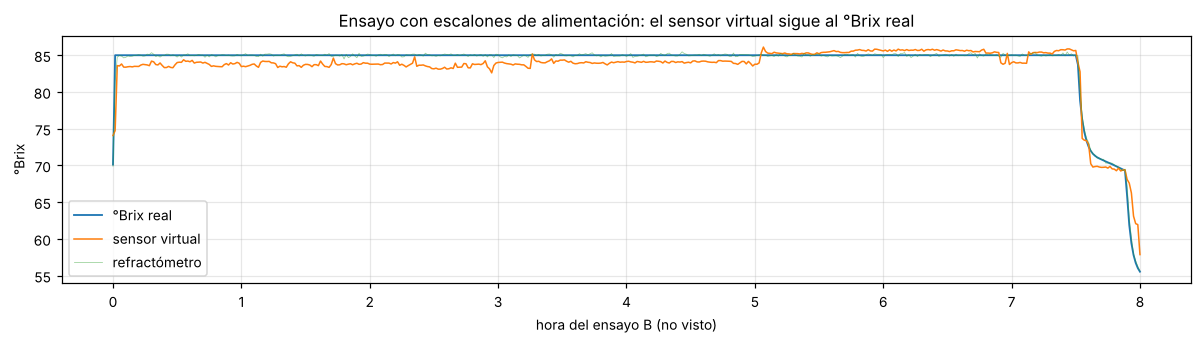

In [5]:
XB=SENS+['Brix_EPE','Brix_MB']; yB='Brix_refract'
# restricciones físicas: +1 = el °Brix solo puede subir con esa variable; -1 = solo puede bajar
mono=[{'F_th':-1,'vapor_th':1}.get(c,0) for c in SENS]+[1,1]
modelos={'Físico (EPE + balance)':(LinearRegression(),['Brix_EPE','Brix_MB']),'Ridge (sensores + físicos)':(Ridge(1.0),XB),
         'Gradient boosting monótono':(HistGradientBoostingRegressor(max_iter=300,min_samples_leaf=40,monotonic_cst=mono,random_state=0),XB)}
filas=[{'modelo':'Ingenuo (°Brix = 70)','MAE prueba':mean_absolute_error(hs.real_Brix[TE],np.full(TE.sum(),70.0)),'MAE ensayo B':mean_absolute_error(hs.real_Brix[ENSB],np.full(ENSB.sum(),70.0))}]
for nom,(m,X) in modelos.items():
    m.fit(hs.loc[TR,X],hs.loc[TR,yB])
    filas.append({'modelo':nom,'MAE prueba':mean_absolute_error(hs.real_Brix[TE],m.predict(hs.loc[TE,X])),'MAE ensayo B':mean_absolute_error(hs.real_Brix[ENSB],m.predict(hs.loc[ENSB,X]))})
tB=pd.DataFrame(filas).set_index('modelo').round(2); print(tB); tB.to_csv(MOD/'comparacion_brix.csv')
mB=modelos['Gradient boosting monótono'][0]
e=hs[ENSB]; fig,ax=plt.subplots(figsize=(11,3.2)); ax.plot(e.t_min/60,e.real_Brix,lw=1.2,label='°Brix real'); ax.plot(e.t_min/60,mB.predict(e[XB]),lw=1,label='sensor virtual')
ax.plot(e.t_min/60,e.Brix_refract,lw=.5,alpha=.5,label='refractómetro'); ax.set_xlabel('hora del ensayo B (no visto)'); ax.set_ylabel('°Brix'); ax.legend(); ax.set_title('Ensayo con escalones de alimentación: el sensor virtual sigue al °Brix real')
fig.tight_layout(); fig.savefig(FIG/'03_brix_ensayo.png'); plt.show()

## 5. Sensor virtual de HMF y color: pocos datos de laboratorio
Aquí está el desafío típico de la industria: solo hay **120 análisis de laboratorio** para entrenar. Se comparan:
- modelos de datos puros (gradient boosting y Ridge sobre los sensores crudos);
- un modelo **con un término de Arrhenius por efecto** (6 coeficientes libres, no negativos);
- el **modelo de caja gris**: la estructura es física y solo se calibran 2 constantes cinéticas (evaporador y tanque).

In [6]:
XH=['zevap_H','ztq_H']; XC=['zevap_C','ztq_C']; XHE=['zH1','zH2','zH3','zH4','zH5','ztq_H']; RAW=SENS+['enfriador','horas_tanque']
res=[]; final={}
for tgt,labc,XF in [('real_HMF','HMF_lab',XH),('real_color','color_lab',XC)]:
    cand=[('Gradient boosting (sensores crudos)',HistGradientBoostingRegressor(max_iter=200,min_samples_leaf=5,random_state=0),RAW),('Ridge (sensores crudos)',Ridge(1.0),RAW)]
    if tgt=='real_HMF': cand.append(('Arrhenius por efecto (6 coef. libres)',LinearRegression(positive=True),XHE))
    cand.append(('Caja gris (2 constantes cinéticas)',LinearRegression(positive=True),XF))
    for nom,m,X in cand:
        m.fit(L.loc[TRL,X],L.loc[TRL,labc]); p=m.predict(L.loc[TEL,X])
        res.append({'variable':tgt.replace('real_',''),'modelo':nom,'MAE':mean_absolute_error(L.loc[TEL,tgt],p),'R2':r2_score(L.loc[TEL,tgt],p)})
        if nom.startswith('Caja gris'): final[tgt]=(m,XF)
        if nom.startswith('Arrhenius'): libre=m
tH=pd.DataFrame(res).set_index(['variable','modelo']); print(tH.round(4)); tH.round(4).to_csv(MOD/'comparacion_hmf_color.csv')
mH,_=final['real_HMF']; mC,_=final['real_color']
print('\nModelo con 6 coeficientes libres (∝ masa retenida de cada efecto, si fuera físico):',np.round(libre.coef_,2))
k=pd.DataFrame({'k0 evaporador':[mH.coef_[0],mC.coef_[0]],'k0 tanque':[mH.coef_[1],mC.coef_[1]],'k0 del simulador':[0.18,0.0011]},index=['HMF [mg/(kg·s)]','color [1/s]'])
print('\nConstantes cinéticas calibradas con el laboratorio (caja gris):'); print(k.round(5)); k.to_csv(MOD/'constantes_cineticas.csv')

                                                   MAE      R2
variable modelo                                               
HMF      Gradient boosting (sensores crudos)    0.8228  0.5697
         Ridge (sensores crudos)                0.7214  0.5538
         Arrhenius por efecto (6 coef. libres)  0.4410  0.8741
         Caja gris (2 constantes cinéticas)     0.5032  0.8946
color    Gradient boosting (sensores crudos)    0.0071  0.4686
         Ridge (sensores crudos)                0.0076  0.5010
         Caja gris (2 constantes cinéticas)     0.0029  0.9394

Modelo con 6 coeficientes libres (∝ masa retenida de cada efecto, si fuera físico): [ 2.88  5.94 16.73  0.    0.    0.18]

Constantes cinéticas calibradas con el laboratorio (caja gris):
                 k0 evaporador  k0 tanque  k0 del simulador
HMF [mg/(kg·s)]        0.16136    0.18749            0.1800
color [1/s]            0.00097    0.00114            0.0011


Los 6 coeficientes libres salen inestables: con 120 análisis no se puede separar el aporte de cada efecto, porque las
temperaturas de los cinco se mueven juntas (colinealidad). Algunos coeficientes dan 0 y otros, valores enormes. El
modelo de caja gris fija esa estructura con la física, y entonces **las constantes que aprende son físicamente
correctas**: se parecen a la constante cinética real del simulador (0,18 para el HMF y 0,0011 para el color). En una
planta real, ese valor se compara con la bibliografía para validar el modelo.

## 6. Curva de aprendizaje: ¿cuántos análisis de laboratorio hacen falta?
Se entrena con 10, 20, 40, 80 y 120 análisis. Un modelo con física necesita muchos menos datos para ser útil, y eso
se traduce en semanas menos de recolección en una planta real.

                         Caja gris (2 constantes)  \
análisis de laboratorio                             
10                                          0.612   
20                                          0.521   
40                                          0.496   
80                                          0.511   
120                                         0.503   

                         Gradient boosting (sensores crudos)  
análisis de laboratorio                                       
10                                                     1.395  
20                                                     1.154  
40                                                     0.948  
80                                                     0.878  
120                                                    0.823  


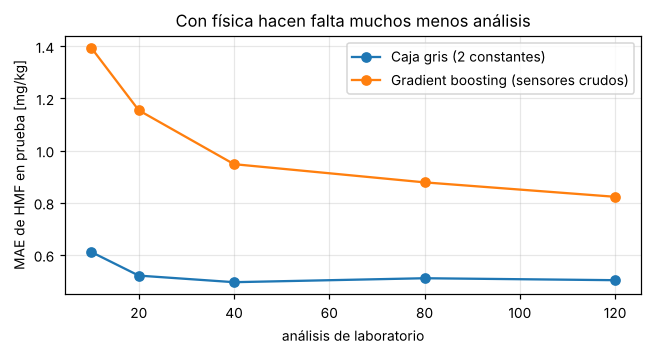

In [7]:
rng=np.random.default_rng(0); ns=[10,20,40,80,120]; curva={'Caja gris (2 constantes)':[],'Gradient boosting (sensores crudos)':[]}
idx=np.where(TRL)[0]
for n in ns:
    a=[];b=[]
    for rep in range(20):
        sel=rng.choice(idx,n,replace=False)
        m1=LinearRegression(positive=True).fit(L.iloc[sel][XH],L.iloc[sel].HMF_lab); a.append(mean_absolute_error(L.loc[TEL,'real_HMF'],m1.predict(L.loc[TEL,XH])))
        m2=HistGradientBoostingRegressor(max_iter=200,min_samples_leaf=min(5,max(2,n//6)),random_state=0).fit(L.iloc[sel][RAW],L.iloc[sel].HMF_lab); b.append(mean_absolute_error(L.loc[TEL,'real_HMF'],m2.predict(L.loc[TEL,RAW])))
    curva['Caja gris (2 constantes)'].append(np.median(a)); curva['Gradient boosting (sensores crudos)'].append(np.median(b))
cv=pd.DataFrame(curva,index=ns); cv.index.name='análisis de laboratorio'; print(cv.round(3))
ax=cv.plot(marker='o',figsize=(6,3.3)); ax.set_ylabel('MAE de HMF en prueba [mg/kg]'); ax.set_title('Con física hacen falta muchos menos análisis'); plt.tight_layout(); plt.savefig(FIG/'04_curva_aprendizaje.png'); plt.show()

## 7. ¿Los modelos respetan la fenomenología?
Se simula un cambio físico sobre los datos de prueba y se mira hacia dónde se mueve la predicción:
- **+10 °C en todas las temperaturas** (vapor más caliente, en parte fuera del rango de entrenamiento): el HMF
  predicho tiene que **subir** en todas las filas.
- **+10 % de alimentación** con el resto igual: el °Brix predicho tiene que **bajar**.

Se cuenta el porcentaje de filas en que cada modelo responde en el sentido correcto.

In [8]:
TT=['Ts','T1','T2','T3','T4','T5']
Lte=L[TEL].copy(); Lup=Lte.copy(); Lup[TT]=Lup[TT]+10
# las presiones se mantienen, así que el °Brix por EPE no cambia: solo cambia la temperatura de reacción
for kk,v in rasgos_calidad(Lup,'H',EAH).items(): Lup[kk]=v
# (en Lte los rasgos vienen del filtro de 15 min; para comparar igual se recalculan también sin filtro)
Lte=Lte.copy()
for kk,v in rasgos_calidad(Lte,'H',EAH).items(): Lte[kk]=v
gb_raw=HistGradientBoostingRegressor(max_iter=200,min_samples_leaf=5,random_state=0).fit(L.loc[TRL,RAW],L.loc[TRL,'HMF_lab'])
ok_fis=(mH.predict(Lup[XH])>mH.predict(Lte[XH])).mean(); ok_gb=(gb_raw.predict(Lup[RAW])>gb_raw.predict(Lte[RAW])).mean()
hte=hs[TE].copy(); hF=hte.copy(); hF['F_th']*=1.10; hF['Brix_MB']=hF.F_th*hF.Bf/np.maximum(1,hF.F_th-4.0*hF.vapor_th)
ok_brix=(mB.predict(hF[XB])<=mB.predict(hte[XB])).mean()
fen=pd.DataFrame({'prueba':['+10 °C → HMF sube','+10 °C → HMF sube','+10 % alimentación → °Brix baja'],'modelo':['Caja gris (HMF)','Gradient boosting (sensores crudos)','Gradient boosting monótono (°Brix)'],
                  '% de filas en el sentido correcto':[ok_fis*100,ok_gb*100,ok_brix*100]}).round(1)
print(fen.to_string(index=False)); fen.to_csv(MOD/'chequeo_fenomenologia_modelos.csv',index=False)
assert ok_fis>0.99 and ok_brix>0.99

                         prueba                              modelo  % de filas en el sentido correcto
              +10 °C → HMF sube                     Caja gris (HMF)                              100.0
              +10 °C → HMF sube Gradient boosting (sensores crudos)                               98.2
+10 % alimentación → °Brix baja  Gradient boosting monótono (°Brix)                              100.0


El modelo de caja gris y el gradient boosting con restricciones de monotonía responden en el sentido correcto en todos
los casos. El gradient boosting sobre sensores crudos **no puede extrapolar**: un árbol devuelve el valor de su última
hoja, así que fuera del rango de entrenamiento la predicción se "aplana" y deja de subir con la temperatura, justo en
la situación de riesgo (vapor más caliente que lo habitual). El término de Arrhenius, en cambio, extrapola con la física.
En un sensor virtual que alimenta decisiones de operación, esa diferencia importa más que unas décimas de error promedio.

## 8. Monitoreo en operación: deriva del modelo
El sensor virtual se valida contra cada análisis de laboratorio. Si el residuo (laboratorio − predicción) se desvía,
el modelo tiene que recalibrarse. Aquí se grafica el residuo de HMF en las campañas de prueba según el ensuciamiento.

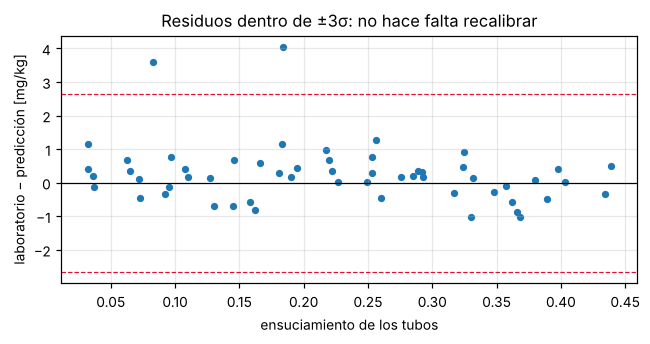

residuo medio 0.253 desvío 0.884


In [9]:
Lr=L[TEL].copy(); Lr['residuo']=Lr.HMF_lab-mH.predict(Lr[XH])
fig,ax=plt.subplots(figsize=(6,3.2)); ax.scatter(Lr.real_foul,Lr.residuo,s=14); ax.axhline(0,color='k',lw=.8)
for k in [1,-1]: ax.axhline(k*3*Lr.residuo.std(),ls='--',color='crimson',lw=.8)
ax.set_xlabel('ensuciamiento de los tubos'); ax.set_ylabel('laboratorio − predicción [mg/kg]'); ax.set_title('Residuos dentro de ±3σ: no hace falta recalibrar'); plt.tight_layout(); plt.savefig(FIG/'05_monitoreo_residuos.png'); plt.show()
print('residuo medio',Lr.residuo.mean().round(3),'desvío',Lr.residuo.std().round(3))

## 9. Exportación para el despliegue en el DCS o SCADA
Se exportan a JSON:
- el gradient boosting monótono de °Brix (árboles);
- las constantes del modelo de caja gris de HMF y color;
- las constantes de los rasgos físicos.

Se verifica que la implementación exportada dé las mismas predicciones que scikit-learn.

In [10]:
def exportar_hgb(m):
    arb=[]
    for it in m._predictors:
        n=it[0].nodes; arb.append({'f':n['feature_idx'].tolist(),'t':[float(v) for v in n['num_threshold']],'l':n['left'].tolist(),'r':n['right'].tolist(),'h':n['is_leaf'].astype(int).tolist(),'v':[float(v) for v in n['value']]})
    return {'base':float(np.ravel(m._baseline_prediction)[0]),'arboles':arb}
def pred_hgb(mj,x):
    s=mj['base']
    for a in mj['arboles']:
        i=0
        while not a['h'][i]: i=a['l'][i] if x[a['f'][i]]<=a['t'][i] else a['r'][i]
        s+=a['v'][i]
    return s
modelo={'filtro_min':VENT,'filtro_calidad_min':VENT_Q,'Tref':TREF,'EaH':EAH,'EaC':EAC,'masas_diseno':MDIS,'economia':4.0,'brix':dict(exportar_hgb(mB),rasgos=XB),
        'hmf':{'rasgos':XH,'coef':mH.coef_.tolist(),'ordenada':float(mH.intercept_)},'color':{'rasgos':XC,'coef':mC.coef_.tolist(),'ordenada':float(mC.intercept_)}}
Xs=hs.loc[TE,XB].values[:300]; dif=np.abs(np.array([pred_hgb(modelo['brix'],x) for x in Xs])-mB.predict(hs.loc[TE,XB].iloc[:300])).max()
print('Diferencia máxima °Brix exportado vs scikit-learn:',dif); assert dif<1e-6
json.dump(modelo,open(MOD/'sensor_virtual.json','w'),separators=(',',':'))
print('Modelo exportado:',(MOD/'sensor_virtual.json').stat().st_size//1024,'kB')

Diferencia máxima °Brix exportado vs scikit-learn: 0.0


Modelo exportado: 689 kB


## 10. Limitaciones y camino a producción
1. **Datos reales:** el modelo se reentrena con el historiador y el laboratorio de la planta. Lo transferible es la
   *metodología*: rasgos físicos, partición temporal, restricciones de monotonía y chequeos de fenomenología.
2. **Ensayos en planta:** sin ensayos (escalones en manual) los datos en lazo cerrado no enseñan la relación °Brix–alimentación.
3. **Calidad de los instrumentos:** el °Brix por EPE depende de que la presión del 5º efecto se mida con precisión
   (a 6 kPa, 0,3 kPa de error son casi 0,6 °C). Vale la pena un transmisor de presión absoluta de buena clase.
4. **Validación continua:** cada análisis de laboratorio sirve para controlar el sensor virtual. Si el residuo sale de
   ±3σ, se marca como "no confiable" y se vuelve al refractómetro o al laboratorio.